# HW2: symbolic regression
Alex Shields and Gopesh Baheti

`symbolic_regression.py` contains the expression trees and GP operators.
This notebook splits the data, runs the experiments, and plots the results.

Following [Koza's preparatory steps](https://www.genetic-programming.com/gppreparatory.html):

1. Terminals are the input variables and integer constants from -5 to 5. Dataset2 mutation can also add real constants.
2. Functions are +, -, *, and protected division, which returns 1 when dividing by zero.
3. Fitness is MSE divided by the target variance plus `1e-9`. Lower is better.
4. Population 1,000, tournament size 4, maximum depth 8. After two elites, each child comes from crossover with probability 0.8 and mutation otherwise.
5. A run stops when training fitness drops below `0.0001` or after 40 generations. Elitism keeps the best tree.

In [15]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

from symbolic_regression import run_gp, get_fitness, EARLY_STOP_THRESHOLD

POPULATION = 1000
GENERATIONS = 40
SEEDS = range(212, 222)
RESULTS = "results.csv"

## Data and splits

Each dataset has 25,000 rows. We hold out 5,000 with split seed 42.
The restricted dataset2 condition keeps rows with distance `x3 >= 0.1` from both splits,
so overlapping rows stay on the same side of the split.

In [16]:
def load_split(dataset, min_distance=None):
    data = np.loadtxt(f"{dataset}.csv", delimiter=",", skiprows=1)
    train, test = train_test_split(data, test_size=5000, random_state=42)
    if min_distance is not None:
        train = train[train[:, 2] >= min_distance]
        test = test[test[:, 2] >= min_distance]
    return train[:, :-1], train[:, -1], test[:, :-1], test[:, -1]

## Experiments

Each condition runs ten seeds. Training error picks the model within a run, and the
held-out rows are only used for scoring afterwards.

Everything goes into `results.csv`. Each row has a `condition` and a `kind`: run scores,
per-generation training error, or held-out predictions. The runs take a while, so the
next cell only loads the CSV. Uncomment its first two lines to rerun.

In [17]:
CONDITIONS = {"Dataset1": load_split("dataset1"),
              "Dataset2 full": load_split("dataset2"),
              "Dataset2 r >= 0.1": load_split("dataset2", min_distance=0.1)}


def run_condition(condition):
    x_train, y_train, x_test, y_test = CONDITIONS[condition]
    tables = []
    for seed in SEEDS:
        random.seed(seed)
        model, history = run_gp(x_train, y_train, x_train.shape[1],
                                real_constants=(condition != "Dataset1"),
                                population_size=POPULATION, generations=GENERATIONS)
        predicted = model.evaluate(x_test)
        tables.append(pd.DataFrame([{
            "kind": "run", "seed": seed, "expression": str(model),
            "train_error": history[-1], "test_error": get_fitness(model, x_test, y_test),
            "test_rmse": root_mean_squared_error(y_test, predicted),
            "nodes": model.size(), "generations": len(history),
            "n_train": len(y_train), "n_test": len(y_test)}]))
        tables.append(pd.DataFrame({"kind": "history", "seed": seed,
                                    "generation": range(len(history)), "train_error": history}))
        points = pd.DataFrame(x_test, columns=[f"x{i + 1}" for i in range(x_test.shape[1])])
        tables.append(points.assign(kind="prediction", seed=seed, actual=y_test, predicted=predicted))
        print(f"{condition}, seed {seed}: {len(history)} generations, "
              f"train error {history[-1]:.6g}", flush=True)
    return pd.concat(tables).assign(condition=condition)

In [18]:
# keep these lines commented if results.csv already exists
tables = [run_condition(condition) for condition in CONDITIONS]
pd.concat(tables).to_csv(RESULTS, index=False)

results = pd.read_csv(RESULTS, low_memory=False)

Dataset1, seed 212: 9 generations, train error 1.66338e-06
Dataset1, seed 213: 7 generations, train error 1.66338e-06
Dataset1, seed 214: 10 generations, train error 4.22507e-06
Dataset1, seed 215: 10 generations, train error 2.4533e-05
Dataset1, seed 216: 10 generations, train error 1.66338e-06
Dataset1, seed 217: 13 generations, train error 1.66338e-06
Dataset1, seed 218: 5 generations, train error 1.66338e-06
Dataset1, seed 219: 6 generations, train error 1.66338e-06
Dataset1, seed 220: 10 generations, train error 3.23759e-05
Dataset1, seed 221: 8 generations, train error 1.66338e-06
Dataset2 full, seed 212: 40 generations, train error 0.8334
Dataset2 full, seed 213: 40 generations, train error 0.0261596
Dataset2 full, seed 214: 40 generations, train error 0.0239311
Dataset2 full, seed 215: 40 generations, train error 0.847764
Dataset2 full, seed 216: 40 generations, train error 0.817347
Dataset2 full, seed 217: 40 generations, train error 0.747574
Dataset2 full, seed 218: 40 genera

## Results

Each row is one run. Normalized errors use the target variance of the split being scored,
and filtering changes that variance, so full and restricted dataset2 errors are on different scales.

In [19]:
def select(kind, condition):
    return results[(results["kind"] == kind) & (results["condition"] == condition)]


results[results["kind"] == "run"].dropna(axis=1, how="all")

,kind,seed,expression,train_error,test_error,test_rmse,nodes,generations,n_train,n_test,condition
0,run,212,((2 * 5) - ((-4 + x1) - ((x1 * (x1 - 4)) - x1))),0.000002,0.000002,2.468772e-02,15.0,9.0,20000.0,5000.0,Dataset1
5010,run,213,(((((x1 * x1) + 3) + ((x1 * x1) - (x1 * x1))) ...,0.000002,0.000002,2.468772e-02,37.0,7.0,20000.0,5000.0,Dataset1
10018,run,214,((((5 + 4) + ((5 - ((x1 * x1) / x1)) - (3 * x1...,0.000004,0.000004,4.001854e-02,33.0,10.0,20000.0,5000.0,Dataset1
15029,run,215,(3 + ((1 * (x1 * ((-1 + -4) + x1))) + ((x1 - -...,0.000025,0.000027,9.790548e-02,33.0,10.0,20000.0,5000.0,Dataset1
20040,run,216,((((((5 * x1) - (5 * x1)) / -4) - -4) + 5) - (...,0.000002,0.000002,2.468772e-02,37.0,10.0,20000.0,5000.0,Dataset1
25051,run,217,(((-4 + x1) * (x1 + (-3 * (x1 / 0)))) + (2 + x1)),0.000002,0.000002,2.468772e-02,15.0,13.0,20000.0,5000.0,Dataset1
30065,run,218,(((-3 + x1) * (-3 + x1)) + 5),0.000002,0.000002,2.468772e-02,9.0,5.0,20000.0,5000.0,Dataset1
35071,run,219,(((((x1 + -5) * x1) - ((5 - -4) * -1)) + (x1 +...,0.000002,0.000002,2.468772e-02,29.0,6.0,20000.0,5000.0,Dataset1
40078,run,220,(((((-2 / 5) / (x1 * -2)) * (x1 * ((4 + 5) / -...,0.000032,0.000032,1.078397e-01,41.0,10.0,20000.0,5000.0,Dataset1
45089,run,221,(((2 - x1) - (((((x1 * (x1 - 5)) + 1) + -2) + ...,0.000002,0.000002,2.468772e-02,29.0,8.0,20000.0,5000.0,Dataset1


## Training error

Each line is one seed. The dashed line marks the stopping threshold.

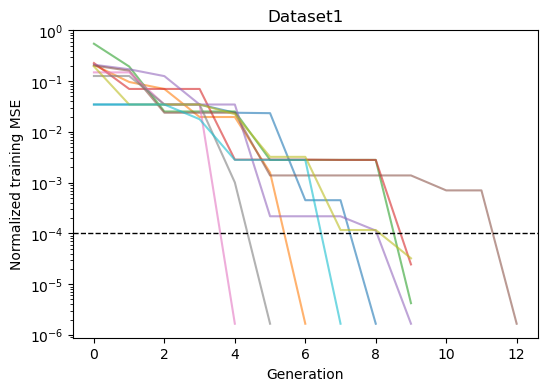

In [20]:
def plot_history(condition):
    seeds = select("history", condition).pivot(
        index="generation", columns="seed", values="train_error")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(seeds.index, seeds.values, alpha=0.6)
    ax.axhline(EARLY_STOP_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax.set(title=condition, xlabel="Generation", ylabel="Normalized training MSE", yscale="log")
    plt.show()


plot_history("Dataset1")

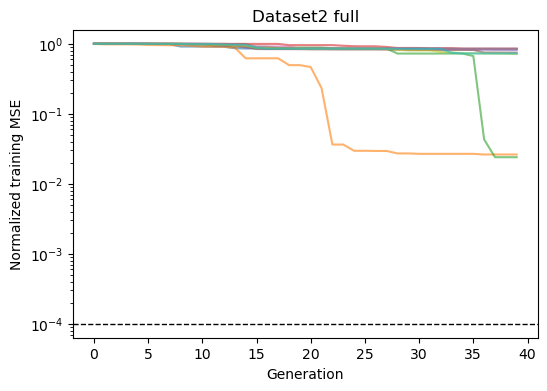

In [21]:
plot_history("Dataset2 full")

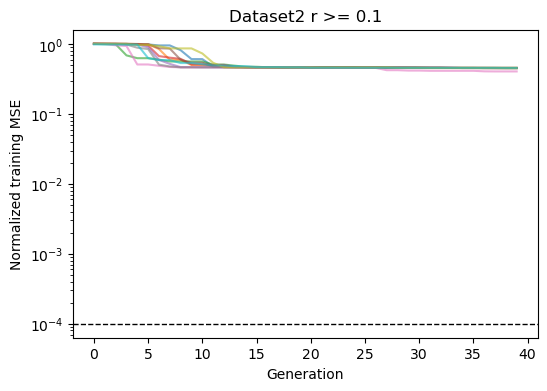

In [22]:
plot_history("Dataset2 r >= 0.1")

## Predictions

[Koza's example](https://www.genetic-programming.com/gpquadraticexample.html)
compares candidate outputs with the target function. Each plot uses the run with the
lowest training error. Dataset1 shows the learned curve. Both dataset2 plots use the
same held-out rows with `x3 >= 0.1`, and the diagonal is perfect prediction.

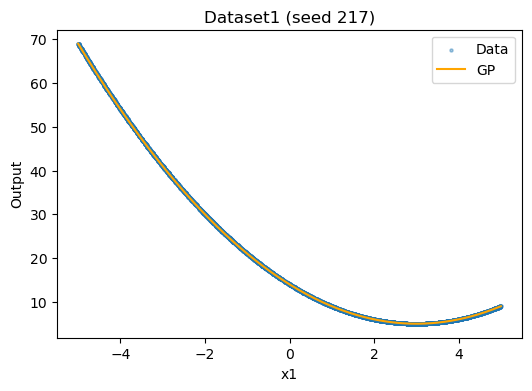

In [23]:
def best_predictions(condition):
    runs = select("run", condition)
    seed = runs.loc[runs["train_error"].idxmin(), "seed"]
    points = select("prediction", condition)
    return seed, points[points["seed"] == seed]


def plot_actual_vs_predicted(condition):
    seed, points = best_predictions(condition)
    points = points[points["x3"] >= 0.1]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(points["actual"], points["predicted"], s=5, alpha=0.4)
    ax.axline((0, 0), slope=1, color="black", linestyle="--")
    ax.set(title=f"{condition} (seed {seed})", xlabel="Actual", ylabel="Predicted")
    plt.show()


seed, points = best_predictions("Dataset1")
points = points.sort_values("x1")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(points["x1"], points["actual"], s=5, alpha=0.4, label="Data")
ax.plot(points["x1"], points["predicted"], color="orange", label="GP")
ax.set(title=f"Dataset1 (seed {seed})", xlabel="x1", ylabel="Output")
ax.legend()
plt.show()

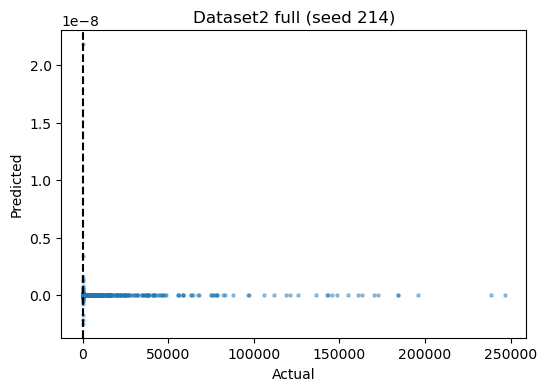

In [24]:
plot_actual_vs_predicted("Dataset2 full")

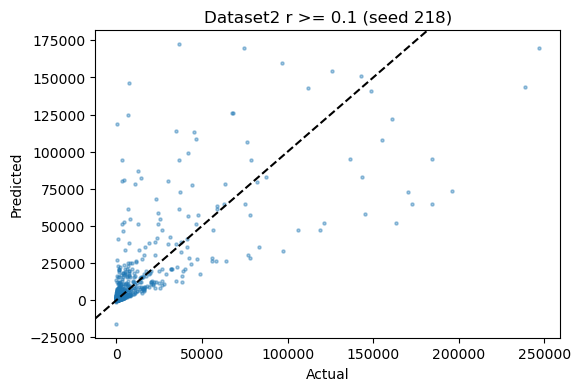

In [25]:
plot_actual_vs_predicted("Dataset2 r >= 0.1")